# chronon demo: the unmodified client on a simulated device

chronon is an independent learning project, not affiliated with IQCC or Quantum Machines. **The device is a simulation; every number below is synthetic.** The client is the public `iqcc-cloud-client` 0.20.0, unmodified; `connect()` imports `scripts/client_patch.py` first, which points it at this site and blocks the upstream domain.

## 1. Connect

In [1]:
import sys

sys.path.insert(0, "../scripts")
from connect import ROOT, connect  # noqa: E402

qc = connect("sim-qpu", token="student-01")

2026-10-20 13:09:21,662 - qm - INFO     - Starting session: 4f3a8952-cbd3-4f8d-b235-f99af98d0b52


## 2. What does this backend offer?

In [2]:
summary = qc.summary()

Backend:         sim-qpu

Status:          🟢 online

Description:     sim-qpu: a SIMULATED single-qubit device for the chronon learning project. All results, timings 
and fridge readings are synthetic.

                                     Available state information                                     
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ datatype ┃ description                                                                            ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ state    │ Latest calibration of the simulated device: T1 per qubit, in microseconds (synthetic). │
└──────────┴────────────────────────────────────────────────────────────────────────────────────────┘

👉 Get latest data as 
 <backand_client>.state.get_latest("<datatype>").data

👉 Latest calibration (state): 13 hours ago (2026-10-19 20:26:32.024303+00:00)

                                           Available on-demand workflows                                           
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ workflow  ┃ description                                                                                         ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ t1        │ T1 (energy relaxation) measurement on the simulated qubit: excite, wait, read out, fit an           │
│           │ exponential decay. Synthetic data.                                                                  │
│ echo      │ Returns its payload. Runs inline in the API and never touches the device; used by the contract      │
│           │ test.                                                                                               │
│ calibrate │ Measure T1 and publish a new 'state' dataset linked to the previous one. Requires the calibrator    │
│           │ role. Synthetic data.                                                                               │
└───────────┴─────────────────────────────────────────────────────────────────────────────────────────────────────┘

👉 Obtain more information about payload specification for each workflow as
<backand_client>.run("<workflow>")

👉 Run on-demand workflow as 
<backand_client>.run("<workflow>", payload)

## 3. A T1 run, and its fit

[13:09:24] t1 ondemand workflow requested submitted to sim-qpu (id =                               ]8;id=760336;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760337;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#416\416]8;;\
           a751e560-9723-4ab0-8dbd-7697d3cfbba5)                                                                   

Output()

           Execution started                                                                       ]8;id=760343;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760344;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#455\455]8;;\

t1 ondemand workflow requested successfully executed

 👍     stdout:

...

2.088

 🕗 ⚛️  QUA execution time (s)

2.081

 ❄ ☃    Fridge info

mxc temperature = 0.01167 K measured just now

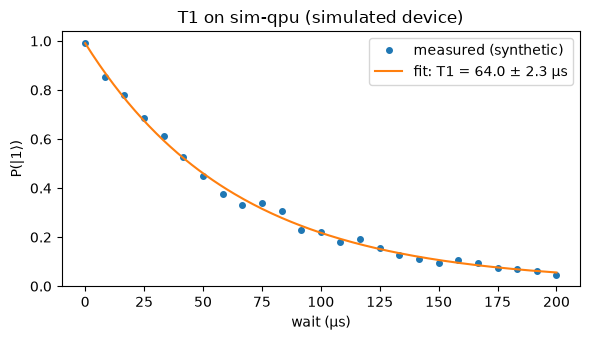

In [3]:
import matplotlib.pyplot as plt
import numpy as np

r = qc.run("t1", {"qubit": 0, "shots": 500}, terminal_output=True)
res = r["result"]
t = np.array(res["wait_us"])
fit = res["fit"]
fine = np.linspace(0, t.max(), 200)
plt.figure(figsize=(6, 3.5))
plt.plot(t, res["excited_population"], "o", ms=4, label="measured (synthetic)")
plt.plot(
    fine,
    fit["amplitude"] * np.exp(-fine / res["t1_us"]) + fit["offset"],
    label=f"fit: T1 = {res['t1_us']:.1f} ± {res['t1_err_us']:.1f} µs",
)
plt.xlabel("wait (µs)")
plt.ylabel("P(|1⟩)")
plt.title("T1 on sim-qpu (simulated device)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Three calibrations, then the trend

A calibrator publishes new `state` datasets, each linked to the previous one. Any student can then follow the drift with the client's own terminal plot.

In [4]:
cal = connect("sim-qpu", token="calibrator-01")
for _ in range(3):
    out = cal.run("calibrate", {"shots": 500})["result"]
    c = out["calibration"]
    ids = f"{out['state_dataset_id']} (parent {out['parent_id']})"
    print(f"state {ids}: T1 = {c['t1_us']:.1f} ± {c['t1_err_us']:.1f} µs")

points = qc.state.trend(
    "$.qubits[0].t1", datatype="state", limit=10, terminal_output=True
)

[13:09:28] calibrate ondemand workflow requested submitted to sim-qpu (id =                        ]8;id=760356;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760357;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#416\416]8;;\
           93d23285-2c1c-4c29-8da3-9d06b0e170cd)                                                                   

Output()

[13:09:29] Execution started                                                                       ]8;id=760362;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760363;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#455\455]8;;\

[13:09:31] Execution finished                                                                      ]8;id=760368;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760369;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#486\486]8;;\

calibrate ondemand workflow requested successfully executed

...

state 27 (parent 26): T1 = 64.9 ± 2.4 µs


[13:09:36] Execution started                                                                       ]8;id=760398;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760399;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#455\455]8;;\

[13:09:38] Execution finished                                                                      ]8;id=760404;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py\computers.py]8;;\:]8;id=760405;file:///Users/oreldanilov/chronon/.venv/lib/python3.12/site-packages/iqcc_cloud_client/computers.py#486\486]8;;\

calibrate ondemand workflow requested successfully executed

state 28 (parent 27): T1 = 66.5 ± 2.2 µs
    ┌──────────────────────────────────────────────────────────────────────────┐
66.5┤                                                                         ▐│
    │                                                                         ▐│
    │                                                                         ▐│
64.8┤                                                                         ▐│
    │▖                                                                        ▐│
    │▌                                                                        ▐│
63.1┤▌                                                                        ▐│
    │▌                                                                        ▐│
    │▌                                                ▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▞│
61.4┤▙▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▞▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀▀                         │
    │▌                                                              

## 5. When a token's window has closed

A student's token is valid only inside its time window. Here we stand in for the window closing mid-session by giving the client from cell 1 the `expired-01` token (its window ended two hours ago). The client prints the service's readable 401 and then raises `ValueError`.

In [5]:
expired = (ROOT / ".tokens" / "expired-01").read_text().strip()
qc.headers["Authorization"] = f"Bearer {expired}"
try:
    qc.run("echo", {"message": "is my window still open?"})
except ValueError as e:
    print(f"\nThe client raised ValueError: {e}")

🚨 Error code 401

Unauthorized

Your access window for backend sim-qpu is 2026-10-20 07:08:23 UTC → 2026-10-20 08:08:23 UTC; it is now 2026-10-20 
10:09:38 UTC, so it closed 2 h 1 min ago. Ask the backend provider for a token covering the current time.


The client raised ValueError: Error code 401 Unauthorized
